# El problema epidémico, las trazas calculadas y una primera corrida del motor

- **Nivel:** 1, Fundamentos
- **Prerrequisitos:** ninguno, este es el cuaderno de entrada
- **Tiempo de lectura:** unos 15 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir qué problema modela el producto de ejemplo y qué datos versiona;
- leer un índice, un manifiesto y una traza de `data/derived/`;
- escribir las ecuaciones del modelo que integra el motor;
- correr el motor de `data-pipeline/pipeline/` sobre un caso y comprobar que reproduce la traza versionada.

## Preparación

El entorno de los cuadernos está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este cuaderno, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Este producto de ejemplo no publica un paquete propio: su método vive en `data-pipeline/pipeline/`, así que el cuaderno importa ese código por su ruta. Un producto importa en cambio su propio paquete de PyPI (`pip install <paquete>==<versión>`).

La siguiente celda importa las herramientas e imprime sus versiones.

In [1]:
# Imprimir las versiones de las herramientas de este cuaderno, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json

import numpy as np
import matplotlib.pyplot as plt

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


El motor no es un paquete instalado: esta celda pone `data-pipeline/` en la ruta de importación e importa el motor (`simulate`) y el registro de parámetros (`SIRParams`). Importarlo, y nunca copiarlo, mantiene un solo motor para el pipeline, las pruebas y estos cuadernos.

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; los módulos del pipeline se importan por su ruta
import sys
from pathlib import Path

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.sir import simulate
from pipeline.io.schema import SIRParams

print(simulate.__module__, SIRParams.__module__)

pipeline.model.sir pipeline.io.schema


## Datos

El problema: ¿cómo se desarrolla una epidemia en una población cerrada, y cuándo despega siquiera? El producto responde con cinco casos (cuatro regímenes y un control) que su pipeline calcula una vez y versiona, de modo que la web y estos cuadernos leen los mismos artefactos.

- Propietario: este repositorio (el ejemplo de la plantilla de producto), https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE.
- Clase de licencia: datos sintéticos que el pipeline produce desde los parámetros de cada manifiesto (`real_or_synthetic` es `synthetic`); no hay conjunto de datos de terceros, así que no aplica licencia de datos, y la licencia MIT del repositorio cubre los artefactos.
- Archivos leídos: `data/derived/manifests/index.json`, `data/derived/manifests/<case>.json` y `data/derived/<case>/trace.json`.

La siguiente celda define dos lectores pequeños y lista los casos del índice.

In [3]:
# Dos lectores de los artefactos versionados: un archivo ausente detiene el cuaderno y nombra su ruta
def read_json(relative):
    return json.loads((ROOT / "data" / "derived" / relative).read_text(encoding="utf-8"))


def params_of(case_id):
    p = read_json(f"manifests/{case_id}.json")["params"]
    return SIRParams(case_id, p["beta"], p["gamma"], p["N"], p["I0"], p["days"])


CASES = [c["case_id"] for c in read_json("manifests/index.json")["cases"]]
OUTBREAKS = [c for c in CASES if c.startswith("EX")]
SUPERCRITICAL = [c for c in OUTBREAKS if params_of(c).beta > params_of(c).gamma]
print(CASES)
print("casos que pueden despegar:", SUPERCRITICAL)

['CTRL_degenerate', 'EX01_subcritical', 'EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']
casos que pueden despegar: ['EX02_epidemic', 'EX03_fast_burn', 'EX04_slow_spread']


El manifiesto de un caso guarda sus parámetros, su semilla, el motor que lo produjo y los rangos en que deben caer sus resultados; la traza guarda la trayectoria decimada (200 puntos como máximo) y un resumen. Esta celda carga el caso de epidemia (`EX02_epidemic`) e imprime los campos que un lector necesita primero.

In [4]:
# Cargar el manifiesto y la traza del caso de epidemia e imprimir lo que contienen
manifest = read_json("manifests/EX02_epidemic.json")
trace = read_json("EX02_epidemic/trace.json")

print("parámetros:", manifest["params"])
print("semilla:", manifest["seed"], "| motor:", manifest["engine"]["model"])
print("puntos de la traza:", len(trace["t"]), "| días cubiertos:", trace["t"][-1])
print("resumen:", trace["summary"])

parámetros: {'beta': 0.55, 'gamma': 0.2, 'N': 100000.0, 'I0': 50.0, 'days': 160}
semilla: 42 | motor: SIR, forward Euler
puntos de la traza: 200 | días cubiertos: 160.0
resumen: {'peak_I': 27345.24, 't_peak': 24.25, 'attack_rate': 0.9237}


La traza son tres curvas en el tiempo: personas susceptibles (S), infectadas (I) y recuperadas (R). Esta celda las dibuja, para ver la forma de la epidemia antes de cualquier ecuación.

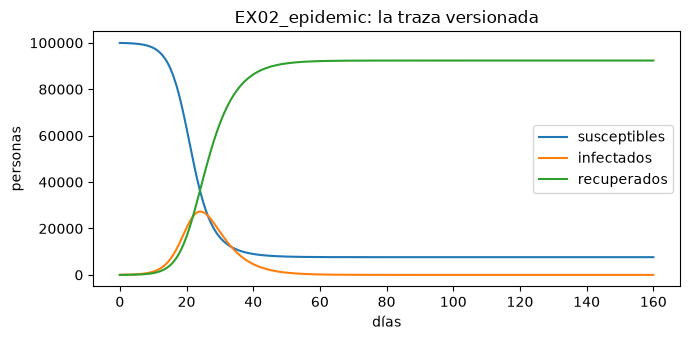

In [5]:
# Dibujar S, I y R de la traza versionada contra el tiempo
fig, ax = plt.subplots(figsize=(7, 3.5))
for key, label in (("S", "susceptibles"), ("I", "infectados"), ("R", "recuperados")):
    ax.plot(trace["t"], trace[key], label=label)
ax.set_xlabel("días")
ax.set_ylabel("personas")
ax.set_title("EX02_epidemic: la traza versionada")
ax.legend()
fig.tight_layout()
plt.show()

## Método

El modelo es el sistema SIR cerrado de Kermack y McKendrick (1927), con los supuestos de libro de texto que recoge la revisión de Hethcote (2000) (población cerrada, mezcla homogénea, determinista):

$$\frac{dS}{dt} = -\beta \frac{S I}{N}, \qquad \frac{dI}{dt} = \beta \frac{S I}{N} - \gamma I, \qquad \frac{dR}{dt} = \gamma I$$

donde $\beta$ es la tasa de contacto, $\gamma$ la tasa de recuperación y $N$ la población. El cociente $R_0 = \beta / \gamma$ decide si una epidemia despega (cuaderno 02 de este tema).

El motor integra el sistema con Euler hacia adelante con paso de un cuarto de día (Hairer, Norsett y Wanner, 1993). Esta celda lo corre, a través del pipeline, con los parámetros del manifiesto.

In [6]:
# Correr el motor del pipeline con los parámetros del manifiesto (una llamada, un caso)
params = params_of("EX02_epidemic")
run = simulate(params)

print("R0 = beta / gamma =", round(params.beta / params.gamma, 2))
print("pasos dados:", len(run.t) - 1)
print("pico de infectados:", round(run.peak_I), "el día", run.t_peak)
print("tasa de ataque:", round(run.attack_rate, 4))

R0 = beta / gamma = 2.75
pasos dados: 640
pico de infectados: 27345 el día 24.25
tasa de ataque: 0.9237


## Resultados

La traza versionada guarda 200 de los 641 puntos que calcula el motor, redondeados a dos decimales. Esta celda toma los valores del motor en los tiempos de la traza y mide la mayor diferencia por compartimento.

In [7]:
# Comparar la corrida nueva con la traza versionada en los tiempos de la traza (el paso es 0,25 días)
index = [round(t / 0.25) for t in trace["t"]]
for key in ("S", "I", "R"):
    fresh = np.array(getattr(run, key))[index]
    print(key, "mayor diferencia, en personas:", float(np.max(np.abs(fresh - np.array(trace[key])))))
print("el resumen coincide:", round(run.attack_rate, 4) == trace["summary"]["attack_rate"])

S mayor diferencia, en personas: 0.0049340308769387775
I mayor diferencia, en personas: 0.004997702378549462
R mayor diferencia, en personas: 0.004988331609638408
el resumen coincide: True


Las diferencias son como máximo media centésima de persona, que es el redondeo de la traza versionada: el artefacto es exactamente lo que produce el motor. La figura de arriba muestra la forma habitual de una epidemia: la curva de infectados sube hasta un pico y cae cuando se agota la reserva de susceptibles. Lo que este cuaderno no muestra es por qué el pico está donde está, ni cuán cerca está el resultado de la respuesta exacta; el siguiente cuaderno desarma el método para eso.

## Resumen

- Los datos del producto son cinco casos calculados, leídos de `data/derived/`, nunca recalculados por la página.
- El motor es el del pipeline, importado por su ruta; reproduce la traza versionada hasta su redondeo.
- Siguiente: el cuaderno 02 de este tema corre el método paso a paso y lo contrasta con una respuesta exacta.

## Referencias

- Kermack, W. O. and McKendrick, A. G. (1927). A contribution to the mathematical theory of epidemics. Proceedings of the Royal Society A. https://doi.org/10.1098/rspa.1927.0118
- Hethcote, H. W. (2000). The mathematics of infectious diseases. SIAM Review. https://doi.org/10.1137/S0036144500371907
- Hairer, E., Norsett, S. P. and Wanner, G. (1993). Solving Ordinary Differential Equations I: Nonstiff Problems. Springer. https://doi.org/10.1007/978-3-540-78862-1
- NumPy, https://pypi.org/project/numpy/ (pinned in `notebooks/requirements.txt`).
- Matplotlib, https://pypi.org/project/matplotlib/ (pinned in `notebooks/requirements.txt`).
- El motor y los casos de este repositorio, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE (`data-pipeline/pipeline/model/sir.py`).

Lo que se atribuye a cada obra es lo que registra la base de investigación del SDD (`docs/design/SDD.md`); el texto de sus páginas no se volvió a leer, solo sus registros de Crossref.